# Projeto da disciplina de Aprendizado de Máquina
## Criatura Lendária 2 - Tiamat

------

Docente: Daniel Roberto Cassar  
Discente: Maria Clara Costa Ferreira  

### Introdução

### Bibliotecas

In [64]:
from sklearn.model_selection import train_test_split, cross_val_score, GroupShuffleSplit, GroupKFold
from sklearn.metrics import root_mean_squared_error, r2_score
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.feature_selection import VarianceThreshold
from sklearn.tree import DecisionTreeRegressor
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from mordred import Calculator, descriptors
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from optuna import create_study
import matplotlib.pyplot as plt
from functools import partial
from rdkit import Chem
import seaborn as sns
import pandas as pd
import numpy as np
import optuna
import warnings

optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings(
    "ignore",
    message = "Skipping features without any observed values",
    category = UserWarning,
)

***************

### Análise exploratória dos dados

In [2]:
# Carregando o dataset extendido de dados de regressão
dados_regressao = pd.read_csv("B3DB_regression_extended.tsv.gz", sep="\t", compression="gzip")

C:\Users\maria2610071\AppData\Local\Temp\ipykernel_12540\622724235.py:2: DtypeWarning: Columns (0: comments) have mixed types. Specify dtype option on import or set low_memory=False.
  dados_regressao = pd.read_csv("B3DB_regression_extended.tsv.gz", sep="\t", compression="gzip")


In [3]:
dados_regressao

,NO.,compound_name,IUPAC_name,SMILES,CID,logBB,Inchi,reference,group,comments,...,SRW10,TSRW10,MW,AMW,WPath,WPol,Zagreb1,Zagreb2,mZagreb1,mZagreb2
0,1,moxalactam,7-[[2-carboxy-2-(4-hydroxyphenyl)acetyl]amino]...,CN1C(=NN=N1)SCC2=C(N3C(C(C3=O)(NC(=O)C(C4=CC=C...,3889.0|,-2.52,InChI=1S/C20H20N6O9S/c1-25-19(22-23-24-25)36-8...,R25|,A,NaN,...,10.893010,87.033695,520.101247,9.287522,4114,62,194,237,13.756944,7.916667
1,2,schembl614298,"(2s,3s,4s,5r)-6-[[(4r,4ar,7s,7ar,12bs)-7-hydro...",CN1CC[C@]23[C@@H]4[C@H]1CC5=C2C(=C(C=C5)OC6[C@...,18595497.0|,-2.15,InChI=1S/C23H27NO9/c1-24-7-6-23-10-3-4-12(25)2...,R25|,A,NaN,...,10.992336,85.350582,461.168581,7.686143,2850,74,198,254,11.229167,6.847222
2,3,morphine-6-glucuronide,"(2s,3s,4s,5r)-6-[[(4r,4ar,7s,7ar,12bs)-9-hydro...",CN1CC[C@]23[C@@H]4[C@H]1CC5=C2C(=C(C=C5)O)O[C@...,9847115.0|,-2.09,InChI=1S/C23H27NO9/c1-24-7-6-23-10-3-5-13(31-2...,R25|,A,NaN,...,10.992504,85.350750,461.168581,7.686143,2802,74,198,254,11.229167,6.847222
3,4,2-[4-(5-bromo-3-methylpyridin-2-yl)butylamino]...,2-[4-(5-bromo-3-methylpyridin-2-yl)butylamino]...,CC1=NC=C(C=C1)CC2CNC(NC2=O)NCCCCC3=NC=C(C=C3C)Br,74041479.0|,-1.88,InChI=1S/C21H28BrN5O/c1-14-9-18(22)13-25-19(14...,R35|,A,NaN,...,10.019536,62.819209,445.147723,7.949066,2666,39,140,158,8.888889,6.222222
4,5,NaN,NaN,c1(c2c3n(c4c(C(N(C)C3)=O)c(Cl)ccc4)cn2)noc(C(O...,nan|,-1.82,"InChI=1S/C16H14ClN5O4/c1-16(24,25)15-19-13(20-...",R35|,A,NaN,...,10.394488,77.720566,375.073432,9.376836,1538,49,148,181,9.423611,5.388889
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1053,1054,2qju,"3-(5,6-dihydrobenzo[b][1]benzazepin-11-yl)prop...",C[NH2+]CCCN1C2=CC=CC=C2CCC3=CC=CC=C31,2995.0|2995.0|2995.0|2995.0|2995.0|2995.0|2995...,1.20,InChI=1S/C18H22N2/c1-19-13-6-14-20-17-9-4-2-7-...,R4|R3|R38|R41|R43|R47|R49|R40|R8|R21|R27|R2|R2...,D,NaN,...,9.832797,61.559435,266.178299,6.337579,759,34,102,120,5.055556,4.611111
1054,1055,promazine,"n,n-dimethyl-3-phenothiazin-10-ylpropan-1-amine",CN(C)CCCN1C2=CC=CC=C2SC3=CC=CC=C31,4926.0|4926.0|4926.0|4926.0|4926.0|4926.0|4926...,1.23,InChI=1S/C17H20N2S/c1-18(2)12-7-13-19-14-8-3-5...,R3|R4|R50|R40|R38|R41|R8|R21|R27|R2|R2|R27|R3|...,D,NaN,...,9.955368,53.748649,284.134720,7.103368,789,31,104,122,5.666667,4.444444
1055,1056,diphenhydramine,"2-benzhydryloxy-n,n-dimethylethanamine",CN(C)CCOC(C1=CC=CC=C1)C2=CC=CC=C2,3100.0|3100.0|3100.0|3100.0|3100.0|3100.0|3100...,1.30,InChI=1S/C17H21NO/c1-18(2)13-14-19-17(15-9-5-3...,R42|R2|R2|R3|R8|R18|R21|R25|R26|R27|R27|R27|R3...,D,NaN,...,9.491073,51.451755,255.162314,6.379058,736,24,90,100,5.694444,4.388889
1056,1057,1225-64-5,3-(2-chlorophenothiazin-10-yl)-n-methylpropan-...,CNCCCN1C2=CC=CC=C2SC3=C1C=C(C=C3)Cl,62875.0|62875.0|62875.0|62875.0|62875.0|62875....,1.40,InChI=1S/C16H17ClN2S/c1-18-9-4-10-19-13-5-2-3-...,R18|R26|R27|R4|R11|R12|R20|R25|R35|R36|R39|R43...,D,NaN,...,9.989436,53.811203,304.080097,8.218381,772,32,104,123,5.666667,4.527778


In [4]:
dados_regressao.columns

Index(['NO.', 'compound_name', 'IUPAC_name', 'SMILES', 'CID', 'logBB', 'Inchi',
       'reference', 'group', 'comments',
       ...
       'SRW10', 'TSRW10', 'MW', 'AMW', 'WPath', 'WPol', 'Zagreb1', 'Zagreb2',
       'mZagreb1', 'mZagreb2'],
      dtype='str', length=1623)

In [5]:
metadados = ["NO.", "compound_name", "logBB", "IUPAC_name", "SMILES", "CID", "Inchi",
       "reference", "group", "comments"]

smiles = dados_regressao["SMILES"]

ATRIBUTOS = dados_regressao.drop(columns = metadados)
TARGET = dados_regressao["logBB"]

In [15]:
porcentagem_ausentes_antes = ATRIBUTOS.isna().sum().sum() / ATRIBUTOS.size * 100

print(f"A porcentagem de descritores faltantes é de {porcentagem_ausentes_antes:.2f}%")

A porcentagem de descritores faltantes é de 10.65%


In [7]:
descritores_faltantes = []

for i in ATRIBUTOS.columns:
    if ATRIBUTOS[i].isna().any():
        descritores_faltantes.append(i)

https://pypi.org/project/mordred/

In [8]:
df_copia = dados_regressao.copy()

calc = Calculator(descriptors, ignore_3D = True)

moleculas = [Chem.MolFromSmiles(smi) for smi in df_copia["SMILES"]]

resultado = calc.pandas(moleculas)
resultado.index = df_copia.index

100%|██████████| 1058/1058 [01:13<00:00, 14.49it/s]


In [30]:
df_copia[descritores_faltantes] = df_copia[descritores_faltantes].fillna(resultado[descritores_faltantes])

In [31]:
ATRIBUTOS_DEPOIS = df_copia[ATRIBUTOS.columns]
porcentagem_posterior = ATRIBUTOS_DEPOIS.isna().sum().sum() / ATRIBUTOS_DEPOIS.size * 100

print(f"A porcentagem de descritores que faltam depois do cálculo usando os SMILES é de {porcentagem_posterior:.2f}%")

A porcentagem de descritores que faltam depois do cálculo usando os SMILES é de 0.00%


In [32]:
faltantes = df_copia.isna().sum()
print(faltantes[faltantes > 0].sort_values(ascending = False))

comments         1049
IUPAC_name        113
compound_name      22
dtype: int64


In [33]:
df_completo = df_copia.reindex(columns = list(ATRIBUTOS_DEPOIS.columns) + [TARGET.name])

### Separação de treino e teste – (train_test_split)


In [34]:
# Aqui se usa a função train_test_split
TAMANHO_TESTE = 0.1
SEMENTE_ALEATORIA = 1912

indices = df_completo.index
indices_treino, indices_teste = train_test_split(
    indices, test_size=TAMANHO_TESTE, random_state=SEMENTE_ALEATORIA
)

df_treino = df_completo.loc[indices_treino]
df_teste = df_completo.loc[indices_teste]

In [35]:
X_treino, y_treino = df_treino[ATRIBUTOS_DEPOIS.columns], df_treino["logBB"]
X_teste, y_teste = df_teste[ATRIBUTOS_DEPOIS.columns], df_teste["logBB"]

### Modelo Baseline

[[-0.08084034]]


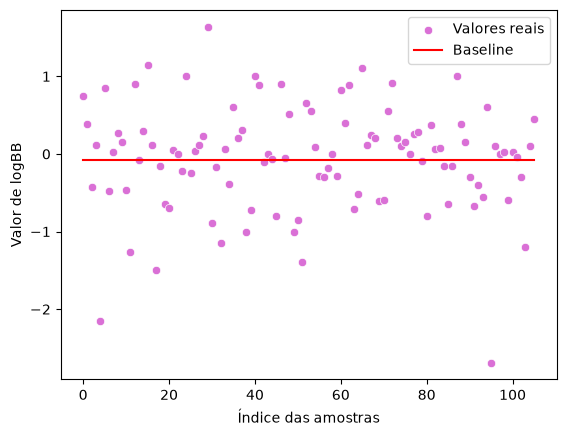

In [36]:
#Aqui se usa a função DummyRegressor

modelo_baseline = DummyRegressor()
modelo_baseline.fit(X_treino, y_treino)

y_real = y_teste
y_previsto = modelo_baseline.predict(X_teste)

sns.scatterplot(
    x = range(len(y_real)),
    y = y_real,
    label = "Valores reais",
    color = "orchid"
)
sns.lineplot(
    x = range(len(y_real)),
    y = y_previsto,
    color="red",
    label = "Baseline"
)

plt.xlabel("Índice das amostras")
plt.ylabel("Valor de logBB")

print(modelo_baseline.constant_)

In [37]:
RMSE = root_mean_squared_error(y_real, y_previsto)
R2 = r2_score(y_real, y_previsto)
print(f"RMSE = {RMSE} unidades de y")
print(f"R² = {R2}")

RMSE = 0.6796107439146724 unidades de y
R² = -0.0019023777748481407


### Separação de treino e teste – (MurckoScaffold)

In [38]:
# Aqui se usa MurckoScaffold e GroupShuffleSplit

def scaffold(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    sc = MurckoScaffold.MurckoScaffoldSmiles(mol=mol)
# Sem anel -> Scaffold vazio e usa o próprio SMILES
    if sc != "":
        return sc
    else:
        return smiles

#Traz os SMILES para o df_completo (com os índices alinhados)
df_completo["SMILES"] = df_copia.loc[df_completo.index, "SMILES"]

df_completo["scaffold"] = df_completo["SMILES"].apply(scaffold)
df_completo = df_completo.dropna(subset=["scaffold"])
grupos = df_completo["scaffold"].astype("category").cat.codes

gss = GroupShuffleSplit(n_splits = 1, test_size = 0.1, random_state = SEMENTE_ALEATORIA)
indices_treino, indices_teste = next(
    gss.split(df_completo[ATRIBUTOS_DEPOIS.columns], df_completo[TARGET.name], groups = grupos)
)

df_treino = df_completo.iloc[indices_treino]
df_teste = df_completo.iloc[indices_teste]

X_treino, y_treino = df_treino[ATRIBUTOS_DEPOIS.columns], df_treino[TARGET.name]
X_teste, y_teste = df_teste[ATRIBUTOS_DEPOIS.columns], df_teste[TARGET.name]

C:\Users\maria2610071\AppData\Local\Temp\ipykernel_12540\2032834265.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_completo["SMILES"] = df_copia.loc[df_completo.index, "SMILES"]
C:\Users\maria2610071\AppData\Local\Temp\ipykernel_12540\2032834265.py:17: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_completo["scaffold"] = df_completo["SMILES"].apply(scaffold)


In [39]:
print(f"Linhas removidas por conta de SMILES inválidos: {len(df_copia) - len(df_completo)}")

Linhas removidas por conta de SMILES inválidos: 0


In [40]:
X = X_treino.to_numpy(dtype=float)
print("NaNs:", np.isnan(X).sum())

NaNs: 166389


### OPTUNA – Árvore de Decisão

In [69]:
NUM_FOLDS = 10

grupos_treino = df_treino["scaffold"]
cv = GroupKFold(n_splits = NUM_FOLDS)

#### Modelo e espaço de busca

In [70]:
def cria_instancia_arvore(trial):
    """Cria uma instância do modelo de árvore de decisão.

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Uma instância do modelo desejado.
    """
    k = trial.suggest_int("k", 15, 500)

    selecao = SelectKBest(score_func = f_regression, k = k)
    
    parametros = {
        # espaço de busca
        "criterion": trial.suggest_categorical("criterion", ["squared_error", "absolute_error"]), #critério de split
        "max_leaf_nodes": trial.suggest_int("max_leaf_nodes", 5, 100),
        "max_depth": trial.suggest_int("max_depth", 2, 20),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 30),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 20),
        "max_features": trial.suggest_float("max_features", 0.1, 1),
        # argumentos fixos
        "random_state": SEMENTE_ALEATORIA,
    }

    modelo = make_pipeline(
        SimpleImputer(strategy = "median"),
        VarianceThreshold(), #Tira colunas constantes
        selecao,
        DecisionTreeRegressor(**parametros)
    )

    return modelo

#### Otimização de Hiperparâmetros

In [75]:
# Aqui se usa cross_val_score
def funcao_objetivo(trial, X, y, cv, grupos):
    """Função objetivo do optuna

    """

    modelo = cria_instancia_arvore(trial)

    metricas = cross_val_score(
        modelo,
        X,
        y,
        scoring="neg_root_mean_squared_error",
        cv=cv,
        groups = grupos_treino,
    )

    return -metricas.mean()

In [76]:
# Aqui se usa create_study

NOME_DO_ESTUDO = "arvore_bbb"

objeto_de_estudo = create_study(
    direction="minimize",
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
    load_if_exists=True,
)

In [77]:
# Aqui se usa a função partial

funcao_objetivo_parcial = partial(
    funcao_objetivo, X=X_treino, y=y_treino, cv = cv, grupos = grupos_treino
)

In [78]:
NUM_TENTATIVAS = 100

objeto_de_estudo.optimize(funcao_objetivo_parcial, n_trials=NUM_TENTATIVAS)

In [79]:
df_arvore = objeto_de_estudo.trials_dataframe()

df_arvore

,number,value,datetime_start,datetime_complete,duration,params_criterion,params_k,params_max_depth,params_max_features,params_max_leaf_nodes,params_min_samples_leaf,params_min_samples_split,state
0,0,0.617479,2026-10-24 21:11:28.850102,2026-10-24 21:11:52.924137,0 days 00:00:24.074035,absolute_error,154.0,9.0,0.593634,8.0,4.0,16.0,COMPLETE
1,1,0.610704,2026-10-24 21:11:53.028464,2026-10-24 21:12:06.866474,0 days 00:00:13.838010,squared_error,258.0,11.0,0.768598,6.0,2.0,10.0,COMPLETE
2,2,0.627816,2026-10-24 21:12:06.937553,2026-10-24 21:12:53.500809,0 days 00:00:46.563256,absolute_error,403.0,19.0,0.899732,13.0,13.0,4.0,COMPLETE
3,3,0.623964,2026-10-24 21:12:53.601021,2026-10-24 21:13:16.647186,0 days 00:00:23.046165,absolute_error,484.0,16.0,0.276740,6.0,12.0,13.0,COMPLETE
4,4,0.605615,2026-10-24 21:13:16.712942,2026-10-24 21:13:34.086605,0 days 00:00:17.373663,squared_error,469.0,5.0,0.958993,8.0,8.0,3.0,COMPLETE
...,...,...,...,...,...,...,...,...,...,...,...,...,...
196,196,0.608959,2026-10-25 00:17:27.676753,2026-10-25 00:17:53.076142,0 days 00:00:25.399389,absolute_error,98.0,4.0,0.922637,78.0,4.0,24.0,COMPLETE
197,197,0.585577,2026-10-25 00:17:53.140633,2026-10-25 00:18:18.642444,0 days 00:00:25.501811,absolute_error,115.0,4.0,0.898886,7.0,4.0,25.0,COMPLETE
198,198,0.591007,2026-10-25 00:18:18.722534,2026-10-25 00:18:41.473415,0 days 00:00:22.750881,absolute_error,71.0,4.0,0.951997,8.0,4.0,25.0,COMPLETE
199,199,0.587437,2026-10-25 00:18:41.572888,2026-10-25 00:19:04.852107,0 days 00:00:23.279219,absolute_error,116.0,5.0,0.968050,7.0,3.0,27.0,COMPLETE


In [80]:
melhor_trial_arvore = objeto_de_estudo.best_trial

print(f"Número do melhor trial: {melhor_trial_arvore.number}")
print(f"Parâmetros do melhor trial: {melhor_trial_arvore.params}")

Número do melhor trial: 183
Parâmetros do melhor trial: {'k': 92, 'criterion': 'absolute_error', 'max_leaf_nodes': 8, 'max_depth': 5, 'min_samples_split': 26, 'min_samples_leaf': 3, 'max_features': 0.951426511624351}


In [81]:
modelo_arvore = cria_instancia_arvore(melhor_trial_arvore)
modelo_arvore.fit(X_treino, y_treino)

y_verdadeiro = y_teste
y_previsao = modelo_arvore.predict(X_teste)

RMSE = root_mean_squared_error(y_verdadeiro, y_previsao)
R2 = r2_score(y_verdadeiro, y_previsao)
print(f"O RMSE foi de {RMSE} unidades de y, enquanto o R2 foi de {R2} unidades de y")

O RMSE foi de 0.7088192450986516 unidades de y, enquanto o R2 foi de 0.3002794435770427 unidades de y


### OPTUNA – Floresta Aleatória

#### Modelo e espaço de busca

In [ ]:
def cria_instancia_floresta(trial):
    """Cria uma instância do modelo de floresta aleatória.

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Uma instância do modelo desejado.
    """
     k = trial.suggest_int("k", 15, 500)

    selecao = SelectKBest(score_func = f_regression, k = k)

    parametros = {
        # espaço de busca
        "n_estimators": trial.suggest_int("n_estimators", 50, 1000, log=True),
        "criterion": trial.suggest_categorical("criterion", ["squared_error", "absolute_error"]), #critério de split
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 30),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 20),
        "max_features": trial.suggest_float("max_features", 0.1, 1),
        # argumentos fixos
        "n_jobs": -1,
        "bootstrap": True,
        "random_state": SEMENTE_ALEATORIA,
    }

     modelo = make_pipeline(
        selecao,
        StandardScaler(),
        DecisionTreeRegressor(**parametros)
    )

    return modelo

#### Otimização de Hiperparâmetros

In [68]:
# Aqui se usa cross_val_score
def funcao_objetivo(trial, X, y, num_folds):
    """Função objetivo do optuna

    """

    modelo = cria_instancia_floresta(trial)

    metricas = cross_val_score(
        modelo,
        X,
        y,
        scoring="neg_root_mean_squared_error",
        cv=cv,
        groups = grupos_treino,
    )

    return -metricas.mean()

In [ ]:
# Aqui se usa create_study

NOME_DO_ESTUDO = "floresta_blood_brain_barrier"

objeto_de_estudo = create_study(
    direction="minimize",
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
    load_if_exists=True,
)

In [ ]:
# Aqui se usa a função partial

funcao_objetivo_parcial = partial(
    funcao_objetivo, X=X_treino, y=y_treino, num_folds=NUM_FOLDS
)

In [ ]:
NUM_TENTATIVAS = 100

objeto_de_estudo.optimize(funcao_objetivo_parcial, n_trials=NUM_TENTATIVAS)

In [58]:
df_floresta = objeto_de_estudo.trials_dataframe()

df_floresta

,number,value,datetime_start,datetime_complete,duration,params_criterion,params_k,params_max_depth,params_max_features,params_max_leaf_nodes,params_min_samples_leaf,params_min_samples_split,state
0,0,0.617479,2026-10-24 21:11:28.850102,2026-10-24 21:11:52.924137,0 days 00:00:24.074035,absolute_error,154,9,0.593634,8,4,16,COMPLETE
1,1,0.610704,2026-10-24 21:11:53.028464,2026-10-24 21:12:06.866474,0 days 00:00:13.838010,squared_error,258,11,0.768598,6,2,10,COMPLETE
2,2,0.627816,2026-10-24 21:12:06.937553,2026-10-24 21:12:53.500809,0 days 00:00:46.563256,absolute_error,403,19,0.899732,13,13,4,COMPLETE
3,3,0.623964,2026-10-24 21:12:53.601021,2026-10-24 21:13:16.647186,0 days 00:00:23.046165,absolute_error,484,16,0.276740,6,12,13,COMPLETE
4,4,0.605615,2026-10-24 21:13:16.712942,2026-10-24 21:13:34.086605,0 days 00:00:17.373663,squared_error,469,5,0.958993,8,8,3,COMPLETE
...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,95,0.595435,2026-10-24 21:46:10.577305,2026-10-24 21:46:27.013729,0 days 00:00:16.436424,squared_error,126,16,0.947373,9,20,8,COMPLETE
96,96,0.602448,2026-10-24 21:46:27.076920,2026-10-24 21:46:46.911408,0 days 00:00:19.834488,absolute_error,85,10,0.950846,6,20,6,COMPLETE
97,97,0.602439,2026-10-24 21:46:47.009366,2026-10-24 21:47:05.528394,0 days 00:00:18.519028,squared_error,127,9,0.954448,9,20,8,COMPLETE
98,98,0.611371,2026-10-24 21:47:05.624933,2026-10-24 21:47:22.217945,0 days 00:00:16.593012,squared_error,130,9,0.973046,9,20,10,COMPLETE


In [59]:
melhor_trial_floresta = objeto_de_estudo.best_trial

print(f"Número do melhor trial: {melhor_trial_floresta.number}")
print(f"Parâmetros do melhor trial: {melhor_trial_floresta.params}")

Número do melhor trial: 95
Parâmetros do melhor trial: {'k': 126, 'criterion': 'squared_error', 'max_leaf_nodes': 9, 'max_depth': 16, 'min_samples_split': 8, 'min_samples_leaf': 20, 'max_features': 0.9473732776555291}


In [ ]:
modelo_floresta = cria_instancia_floresta(melhor_trial_floresta)
modelo_floresta.fit(X_treino, y_treino)

y_verdadeiro = y_teste
y_previsao = modelo_floresta.predict(X_teste)

RMSE = root_mean_squared_error(y_verdadeiro, y_previsao)

RMSE

### OPTUNA - K-Nearest Neighbors 

#### Modelo e espaço de busca

In [ ]:
def cria_instancia_knn(trial):
    """Cria uma instância do modelo.

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Uma instância do modelo desejado.
    """
     k = trial.suggest_int("k", 15, 500)

    selecao = SelectKBest(score_func = f_regression, k = k)

    parametros = {
        # espaço de busca
        "n_neighbors": trial.suggest_int("n_neighbors", 3, 200, log = True),
        "weights": trial.suggest_categorical("weights", ["uniform", "distance"]),
        "metric": trial.suggest_categorical("metric", ["euclidean", "manhattan", "minkowski"]),
        # argumentos fixos
        "n_jobs": -1,
    }
    if parametros["metric"] == "minkowski":
            parametros["p"] = trial.suggest_int("p", 1, 2)
         
    modelo = make_pipeline(
        StandardScaler(),
        KNeighborsRegressor(**parametros)
    )

    return modelo

#### Otimização de Hiperparâmetros

In [ ]:
funcao_objetivo(trial, X, y, NUM_FOLDS, cria_instancia_knn)

In [ ]:
NOME_DO_ESTUDO = "knn_blood_brain_barrier"

objeto_de_estudo = create_study(
    direction="minimize",
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
    load_if_exists=True,
)

In [ ]:
funcao_objetivo_parcial = partial(
    funcao_objetivo, X=X_treino, y=y_treino, num_folds=NUM_FOLDS
)

### OPTUNA -

https://github.com/theochem/B3DB

https://youtu.be/EeOCGvy2pmQ?si=LXvzV68SDoPXUPjH

https://pypi.org/project/mordredcommunity/

https://medium.com/data-hackers/feature-engineering-t%C3%A9cnicas-para-lidar-com-dados-faltantes-em-um-projeto-de-ci%C3%AAncia-de-dados-debdd57eb662

https://medium.com/@walter_sperat/ using-optuna-with-sklearn-the-right-way-part-1-6b4ad0ab2451

https://peregodomingos.medium.com/lidando-com-dados-ausentes-no-pandas-58fae8fbe4d2